In [ ]:
!pip install librosa soundfile scikit-learn seaborn -q

In [ ]:
!pip install -q kaggle


In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import userdata

KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN").strip()

print("Kaggle authentication loaded successfully!")

Kaggle authentication loaded successfully!


In [ ]:
!pip install -q kaggle


In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

print("Kaggle configured successfully!")

Kaggle configured successfully!


In [ ]:
!kaggle datasets download -d muhammadridhoisdi/audio-recognition-open-and-close -p /content/kaggle_data --unzip

Dataset URL: https://www.kaggle.com/datasets/muhammadridhoisdi/audio-recognition-open-and-close
License(s): apache-2.0
100% 239M/239M [00:03<00:00, 79.4MB/s]



In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

print("Kaggle token configured!")

Kaggle token configured!


In [ ]:
!kaggle datasets download -d muhammadridhoisdi/audio-recognition-open-and-close -p /content/kaggle_data --unzip

Dataset URL: https://www.kaggle.com/datasets/muhammadridhoisdi/audio-recognition-open-and-close
License(s): apache-2.0
100% 239M/239M [00:02<00:00, 93.9MB/s]



In [ ]:
!pip install -q -U kagglehub

In [ ]:
from google.colab import userdata

token = userdata.get("KAGGLE_API_TOKEN")

print("Secret found:", token is not None)
print("Token format:", token[:5] + "..." if token else "NOT FOUND")

Secret found: True
Token format: KGAT_...


In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "muhammadridhoisdi/audio-recognition-open-and-close"
)

print("Dataset downloaded to:")
print(path)

100%|██████████| 239M/239M [00:02<00:00, 102MB/s]

Extracting files...


Dataset downloaded to:
/root/.cache/kagglehub/datasets/muhammadridhoisdi/audio-recognition-open-and-close/versions/2


In [ ]:
from google.colab import userdata

token = userdata.get('KAGGLE_API_TOKEN')

print("Secret found:", token is not None)

Secret found: True


In [ ]:
token = "".join(token.split())

print("Token format:", token[:5] + "..." + token[-3:])

Token format: KGAT_...42a


In [ ]:
import os

os.environ["KAGGLE_API_TOKEN"] = token

In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "muhammadridhoisdi/audio-recognition-open-and-close"
)

print("Dataset downloaded!")
print(path)

Using Colab cache for faster access to the 'audio-recognition-open-and-close' dataset.
Dataset downloaded!
/kaggle/input/audio-recognition-open-and-close


In [ ]:
print("Secret found:", token is not None)

Secret found: True


In [ ]:
import os
import glob

dataset_path = path

wav_files = glob.glob(
    dataset_path + "/**/*.wav",
    recursive=True
)

print("Total WAV files:", len(wav_files))

for file in wav_files[:10]:
    print(file)

Total WAV files: 3010
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-898.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-180.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-697.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-500.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-840.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-26.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-41.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-332.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-858.wav
/kaggle/input/audio-recognition-open-and-close/audio-open-close/noise/noise-944.wav


In [ ]:
from collections import Counter

labels = [
    os.path.basename(os.path.dirname(file))
    for file in wav_files
]

print(Counter(labels))

Counter({'noise': 1010, 'open': 1000, 'close': 1000})


In [ ]:
import librosa
import numpy as np

SAMPLE_RATE = 16000
DURATION = 2
N_MFCC = 40

def extract_mfcc(file_path):

    try:
        # Load audio
        audio, sr = librosa.load(
            file_path,
            sr=SAMPLE_RATE,
            duration=DURATION
        )

        # Make every audio file the same length
        required_length = SAMPLE_RATE * DURATION

        if len(audio) < required_length:
            audio = np.pad(
                audio,
                (0, required_length - len(audio))
            )
        else:
            audio = audio[:required_length]

        # Extract MFCC
        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=N_MFCC
        )

        return mfcc

    except Exception as e:
        print("Error:", file_path, e)
        return None

In [ ]:
X = []
y = []

for i, file in enumerate(wav_files):

    label = os.path.basename(
        os.path.dirname(file)
    )

    mfcc = extract_mfcc(file)

    if mfcc is not None:
        X.append(mfcc)
        y.append(label)

    if (i + 1) % 250 == 0:
        print(f"{i + 1}/{len(wav_files)} files processed")

X = np.array(X)
y = np.array(y)

print("\nFeature shape:", X.shape)
print("Labels shape:", y.shape)

250/3010 files processed
500/3010 files processed
750/3010 files processed
1000/3010 files processed
1250/3010 files processed
1500/3010 files processed
1750/3010 files processed
2000/3010 files processed
2250/3010 files processed
2500/3010 files processed
2750/3010 files processed
3000/3010 files processed

Feature shape: (3010, 40, 63)
Labels shape: (3010,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

print("Classes:")
for i, class_name in enumerate(encoder.classes_):
    print(i, "=", class_name)

Classes:
0 = close
1 = noise
2 = open


In [ ]:
X = X[..., np.newaxis]

print("CNN input shape:", X.shape)

CNN input shape: (3010, 40, 63, 1)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 2408
Testing samples: 602


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

num_classes = len(encoder.classes_)

model = models.Sequential([

    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 38, 61, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 38, 61, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 17, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 17, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 14, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 6, 12, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6, 12, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,995 (1.48 MB)

 Trainable params: 388,547 (1.48 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=32,
    verbose=1
)

Epoch 1/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 14s 189ms/step - accuracy: 0.9268 - loss: 0.3275 - val_accuracy: 0.6411 - val_loss: 0.5564
Epoch 2/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 20s 188ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 0.8278 - val_loss: 0.3206
Epoch 3/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 160ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 0.1083
Epoch 4/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 174ms/step - accuracy: 1.0000 - loss: 6.5626e-04 - val_accuracy: 1.0000 - val_loss: 0.0202
Epoch 5/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 21s 182ms/step - accuracy: 1.0000 - loss: 5.0613e-04 - val_accuracy: 1.0000 - val_loss: 0.0030
Epoch 6/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 177ms/step - accuracy: 1.0000 - loss: 3.1802e-04 - val_accuracy: 1.0000 - val_loss: 5.5869e-04
Epoch 7/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 168ms/step - accuracy: 1.0000 - loss: 4.8436e-04 - val_accuracy: 1.0000 - val_loss: 9.0589e-05
Epoch 8/20
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 167ms/step - accuracy: 1.0000 -

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

Test Accuracy: 100.0 %
Test Loss: 0.0


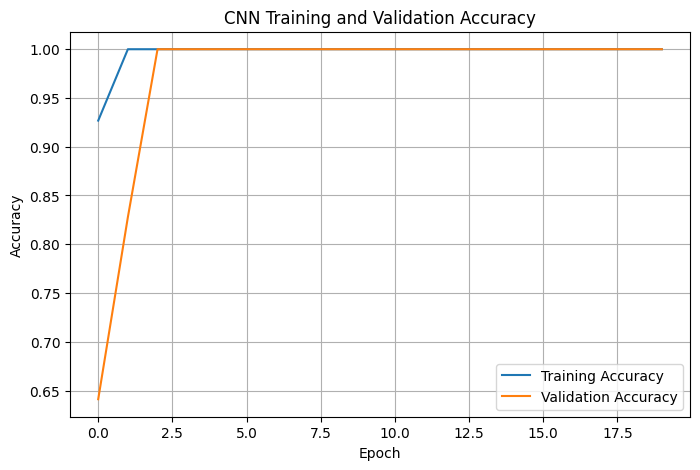

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

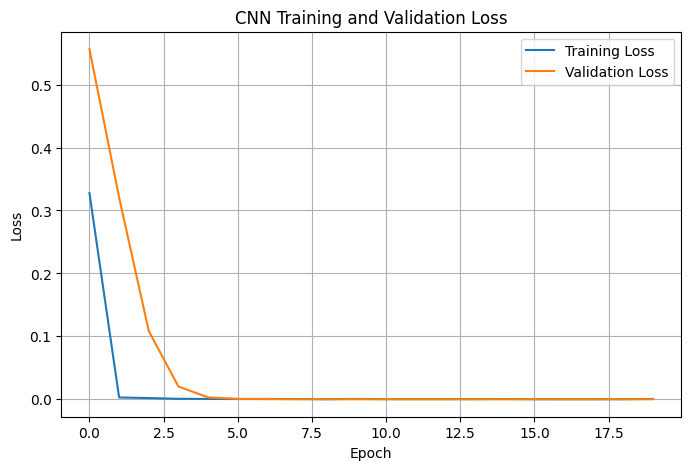

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step


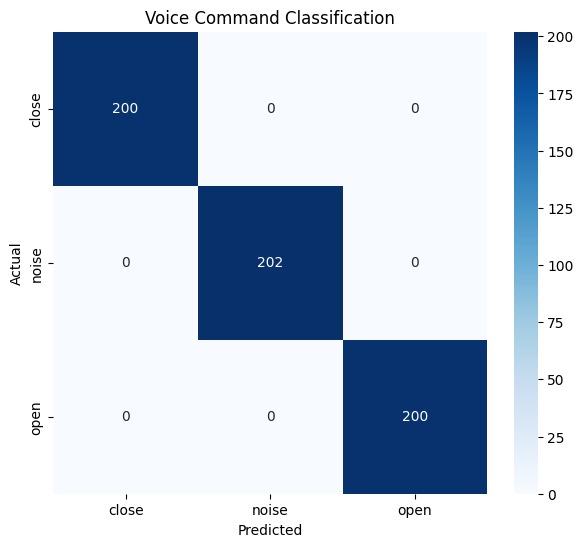

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np

predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Voice Command Classification")

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=encoder.classes_
    )
)

              precision    recall  f1-score   support

       close       1.00      1.00      1.00       200
       noise       1.00      1.00      1.00       202
        open       1.00      1.00      1.00       200

    accuracy                           1.00       602
   macro avg       1.00      1.00      1.00       602
weighted avg       1.00      1.00      1.00       602



In [ ]:
from google.colab import files

print("Upload your voice recording (.wav)")

uploaded_audio = files.upload()

test_audio = list(uploaded_audio.keys())[0]

print("Testing file:", test_audio)

Upload your voice recording (.wav)


Saving open_voice.wav.ogg to open_voice.wav.ogg
Testing file: open_voice.wav.ogg


In [ ]:
mfcc = extract_mfcc(test_audio)

mfcc = mfcc[np.newaxis, ..., np.newaxis]

prediction = model.predict(mfcc, verbose=0)

predicted_index = np.argmax(prediction)

predicted_class = encoder.inverse_transform(
    [predicted_index]
)[0]

confidence = prediction[0][predicted_index]

print("--------------------------------")
print("AI VOICE RECOGNITION")
print("--------------------------------")
print("Predicted command:", predicted_class.upper())
print("Confidence:", round(confidence * 100, 2), "%")

/tmp/ipykernel_612/3213388152.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


--------------------------------
AI VOICE RECOGNITION
--------------------------------
Predicted command: OPEN
Confidence: 99.99 %


In [ ]:
print(voice_door_control)

NameError: name 'voice_door_control' is not defined

In [ ]:
def voice_door_control(command, confidence, threshold=0.70):

    print("\n========== DOOR CONTROL ==========")

    # Safety check
    if confidence < threshold:
        print("Low confidence.")
        print("Door remains CLOSED.")
        return "CLOSED"

    command = command.lower().strip()

    # OPEN command
    if "open" in command:
        print("Command recognized: OPEN")
        print("Door → OPEN")
        return "OPEN"

    # CLOSE command
    elif "close" in command:
        print("Command recognized: CLOSE")
        print("Door → CLOSED")
        return "CLOSED"

    # Unknown command
    else:
        print("Unknown command.")
        print("Door remains CLOSED.")
        return "CLOSED"

print("Door control function defined successfully!")

Door control function defined successfully!


In [ ]:
predicted_class = encoder.inverse_transform(
    [predicted_index]
)[0]

confidence = prediction[0][predicted_index]

In [ ]:
door_status = voice_door_control(
    predicted_class,
    confidence
)

print("\nFinal Door Status:", door_status)


========== DOOR CONTROL ==========
Command recognized: OPEN
Door → OPEN

Final Door Status: OPEN


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import clear_output
import time

def door_simulation(command, confidence, threshold=0.70):

    command = command.lower().strip()

    # Safety check
    if confidence < threshold:
        status = "DOOR CLOSED"
        door_open = False

    elif "open" in command:
        status = "DOOR OPEN"
        door_open = True

    elif "close" in command:
        status = "DOOR CLOSED"
        door_open = False

    else:
        status = "UNKNOWN COMMAND"
        door_open = False

    # Create door
    fig, ax = plt.subplots(figsize=(6, 6))

    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.set_aspect("equal")
    ax.axis("off")

    # Wall
    ax.add_patch(
        Rectangle((1, 1), 8, 8, fill=False, linewidth=3)
    )

    if door_open:

        # Open door - moved to the side
        ax.add_patch(
            Rectangle((1, 1), 2, 7, fill=False, linewidth=4)
        )

        ax.text(
            5, 9.3,
            "DOOR OPEN",
            ha="center",
            fontsize=18
        )

    else:

        # Closed door
        ax.add_patch(
            Rectangle((3, 1), 4, 7, fill=False, linewidth=4)
        )

        ax.text(
            5, 9.3,
            "DOOR CLOSED",
            ha="center",
            fontsize=18
        )

    ax.text(
        5, 0.3,
        f"Command: {command.upper()} | Confidence: {confidence*100:.1f}%",
        ha="center",
        fontsize=11
    )

    plt.show()

    return status

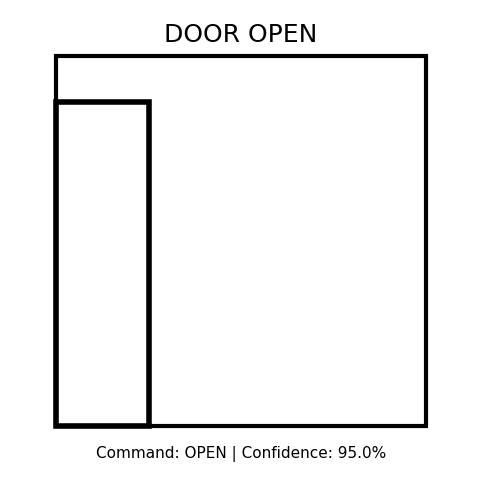

'DOOR OPEN'

In [ ]:
door_simulation("open", 0.95)


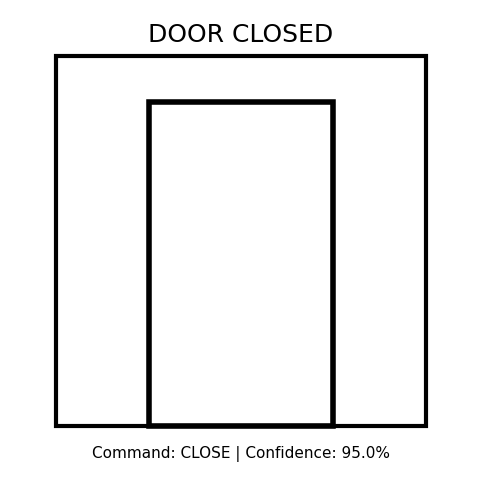

'DOOR CLOSED'

In [ ]:
door_simulation("close", 0.95)

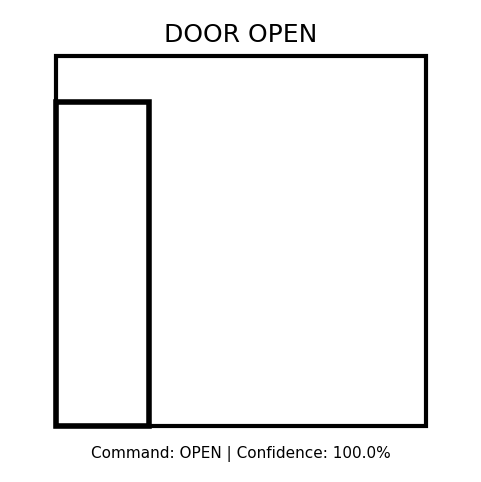

Final Status: DOOR OPEN


In [ ]:
door_status = door_simulation(
    predicted_class,
    confidence
)

print("Final Status:", door_status)

In [ ]:
from google.colab import files

print("Upload your voice recording (.wav)")

uploaded_audio = files.upload()

test_audio = list(uploaded_audio.keys())[0]

mfcc = extract_mfcc(test_audio)
mfcc = mfcc[np.newaxis, ..., np.newaxis]

prediction = model.predict(mfcc, verbose=0)

predicted_index = np.argmax(prediction)

predicted_class = encoder.inverse_transform(
    [predicted_index]
)[0]

confidence = prediction[0][predicted_index]

print("Predicted command:", predicted_class.upper())
print("Confidence:", round(confidence * 100, 2), "%")

Upload your voice recording (.wav)


Saving open_voice.wav.ogg to open_voice.wav (1).ogg


/tmp/ipykernel_612/3213388152.py:12: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Predicted command: OPEN
Confidence: 99.99 %


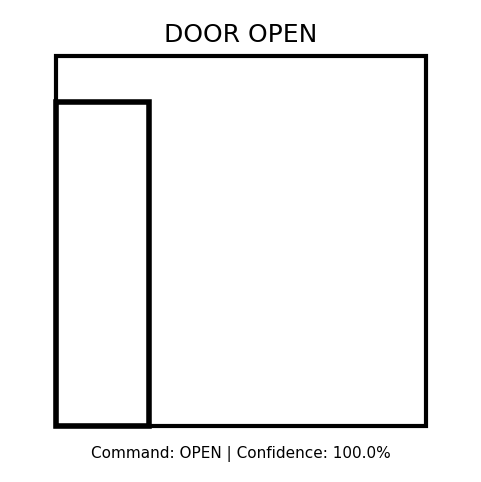

Final Door Status: DOOR OPEN


In [ ]:
door_status = door_simulation(
    predicted_class,
    confidence
)

print("Final Door Status:", door_status)


In [ ]:
import os

AUTHORIZED_DIR = "/content/authorized_voice"
UNAUTHORIZED_DIR = "/content/unauthorized_voice"

os.makedirs(AUTHORIZED_DIR, exist_ok=True)
os.makedirs(UNAUTHORIZED_DIR, exist_ok=True)

print("Folders created!")
print("Authorized:", AUTHORIZED_DIR)
print("Unauthorized:", UNAUTHORIZED_DIR)

Folders created!
Authorized: /content/authorized_voice
Unauthorized: /content/unauthorized_voice


In [ ]:
import os
import shutil
from google.colab import files

In [ ]:
print("Select ALL your authorized voice recordings.")
print("You can select both OPEN and CLOSE files together.")

uploaded = files.upload()

for filename in uploaded.keys():
    shutil.move(
        filename,
        os.path.join(AUTHORIZED_DIR, filename)
    )

print("\nUploaded authorized files:")
for filename in os.listdir(AUTHORIZED_DIR):
    print(filename)

Select ALL your authorized voice recordings.
You can select both OPEN and CLOSE files together.


Saving close_voice.wav.ogg to close_voice.wav.ogg
Saving open_voice.wav.ogg to open_voice.wav (2).ogg

Uploaded authorized files:
close_voice.wav.ogg
open_voice.wav (2).ogg


In [ ]:
from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

AUTHORIZED_DIR = "/content/authorized_voice"
UNAUTHORIZED_DIR = "/content/drive/MyDrive/AI Door Project/unauthorized_voice"

print("Authorized folder exists:", os.path.exists(AUTHORIZED_DIR))
print("Unauthorized folder exists:", os.path.exists(UNAUTHORIZED_DIR))

Authorized folder exists: True
Unauthorized folder exists: True


In [ ]:
import os

print("Folders/files currently in /content:\n")

for item in os.listdir("/content"):
    print(item)

Folders/files currently in /content:

.config
drive
kaggle_data
open_voice.wav.ogg
open_voice.wav (1).ogg
unauthorized_voice
authorized_voice
sample_data


In [ ]:
import os

wav_files = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".wav"):
            wav_files.append(os.path.join(root, file))

print("WAV files found in Google Drive:\n")

for file in wav_files:
    print(file)

print("\nTotal WAV files:", len(wav_files))


WAV files found in Google Drive:


Total WAV files: 0


In [ ]:
import kagglehub

path = kagglehub.dataset_download(
    "muhammadridhoisdi/audio-recognition-open-and-close"
)

print("Dataset downloaded!")
print(path)

Using Colab cache for faster access to the 'audio-recognition-open-and-close' dataset.
Dataset downloaded!
/kaggle/input/audio-recognition-open-and-close


In [ ]:
import os
import glob
import shutil

AUTHORIZED_DIR = "/content/authorized_voice"
os.makedirs(AUTHORIZED_DIR, exist_ok=True)

# Find all WAV files in the downloaded Kaggle dataset
wav_files = glob.glob(
    path + "/**/*.wav",
    recursive=True
)

# Copy only OPEN and CLOSE recordings
authorized_files = []

for file in wav_files:
    folder_name = os.path.basename(os.path.dirname(file)).lower()

    if folder_name in ["open", "close"]:
        destination = os.path.join(
            AUTHORIZED_DIR,
            os.path.basename(file)
        )
        shutil.copy2(file, destination)
        authorized_files.append(destination)

print("Authorized recordings restored!")
print("Total authorized WAV files:", len(authorized_files))

for file in authorized_files[:20]:
    print(os.path.basename(file))

Authorized recordings restored!
Total authorized WAV files: 2000
open-814.wav
open-920.wav
open-767.wav
open-937.wav
open-537.wav
open-406.wav
open-837.wav
open-79.wav
open-642.wav
open-957.wav
open-740.wav
open-67.wav
open-269.wav
open-20.wav
open-106.wav
open-799.wav
open-173.wav
open-699.wav
open-209.wav
open-112.wav


In [ ]:
import os

print("Authorized recordings:")
print("Total files:", len(os.listdir(AUTHORIZED_DIR)))
print()

for filename in os.listdir(AUTHORIZED_DIR)[:20]:
    print(filename)


Authorized recordings:
Total files: 2002

close-12 - Copy.wav
open-839.wav
open-959.wav
open-633.wav
open-543.wav
open-46.wav
close-921.wav
close-776.wav
open-409.wav
open-8.wav
close-784.wav
close-190.wav
close-943.wav
close-273.wav
close-300.wav
open-348.wav
open-846.wav
open-314.wav
open-26.wav
close-183.wav


In [ ]:
import os

UNAUTHORIZED_DIR = "/content/drive/MyDrive/AI Door Project/unauthorized_voice"

print("Unauthorized folder exists:", os.path.exists(UNAUTHORIZED_DIR))

if os.path.exists(UNAUTHORIZED_DIR):
    files = [
        f for f in os.listdir(UNAUTHORIZED_DIR)
        if f.lower().endswith(".wav")
    ]

    print("Total unauthorized WAV files:", len(files))
    print("\nFiles:")

    for f in files[:20]:
        print(f)


Unauthorized folder exists: True
Total unauthorized WAV files: 0

Files:


In [ ]:
import os
import subprocess

UNAUTHORIZED_DIR = "/content/drive/MyDrive/AI Door Project/unauthorized_voice"
CONVERTED_DIR = "/content/unauthorized_voice_wav"

os.makedirs(CONVERTED_DIR, exist_ok=True)

m4a_files = [
    f for f in os.listdir(UNAUTHORIZED_DIR)
    if f.lower().endswith(".m4a")
]

print("M4A files found:", len(m4a_files))

for filename in m4a_files:
    input_path = os.path.join(UNAUTHORIZED_DIR, filename)

    output_name = os.path.splitext(filename)[0] + ".wav"
    output_path = os.path.join(CONVERTED_DIR, output_name)

    subprocess.run([
        "ffmpeg", "-y",
        "-i", input_path,
        "-ar", "16000",
        "-ac", "1",
        output_path
    ], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

print("\nConversion completed!")

wav_files = [
    f for f in os.listdir(CONVERTED_DIR)
    if f.lower().endswith(".wav")
]

print("Converted WAV files:", len(wav_files))

for f in wav_files[:20]:
    print(f)

M4A files found: 41

Conversion completed!
Converted WAV files: 41
Open.wav-2.wav
Close.wav-6.wav
Open.wav-8.wav
Close.wav-2.wav
Close.wav-9.wav
Close.wav-18.wav
2.wav
Close.wav-8.wav
Close.wav-15.wav
Open.wav-10.wav
Voice 033.wav
Close.wav-17.wav
Close.wav-12.wav
Close.wav-5.wav
Close.wav-7.wav
Open.wav-4.wav
Close.wav-4.wav
Close.wav-11.wav
Close.wav-1.wav
Open.wav-7.wav


In [ ]:
print("Unauthorized WAV files:", len(wav_files))

for f in wav_files[:20]:
    print(f)

Unauthorized WAV files: 41
Open.wav-2.wav
Close.wav-6.wav
Open.wav-8.wav
Close.wav-2.wav
Close.wav-9.wav
Close.wav-18.wav
2.wav
Close.wav-8.wav
Close.wav-15.wav
Open.wav-10.wav
Voice 033.wav
Close.wav-17.wav
Close.wav-12.wav
Close.wav-5.wav
Close.wav-7.wav
Open.wav-4.wav
Close.wav-4.wav
Close.wav-11.wav
Close.wav-1.wav
Open.wav-7.wav


In [ ]:
import librosa
import os

print("Checking unauthorized recordings...\n")

for filename in wav_files:
    file_path = os.path.join(CONVERTED_DIR, filename)

    try:
        audio, sr = librosa.load(file_path, sr=None)
        duration = len(audio) / sr

        print(f"{filename}  →  {duration:.2f} seconds")

    except Exception as e:
        print(f"ERROR: {filename} → {e}")

Checking unauthorized recordings...

Open.wav-2.wav  →  2.30 seconds
Close.wav-6.wav  →  1.49 seconds
Open.wav-8.wav  →  1.44 seconds
Close.wav-2.wav  →  1.58 seconds
Close.wav-9.wav  →  1.35 seconds
Close.wav-18.wav  →  2.04 seconds
2.wav  →  3.00 seconds
Close.wav-8.wav  →  1.46 seconds
Close.wav-15.wav  →  2.88 seconds
Open.wav-10.wav  →  2.16 seconds
Voice 033.wav  →  2.25 seconds
Close.wav-17.wav  →  1.97 seconds
Close.wav-12.wav  →  1.49 seconds
Close.wav-5.wav  →  1.67 seconds
Close.wav-7.wav  →  1.83 seconds
Open.wav-4.wav  →  1.90 seconds
Close.wav-4.wav  →  1.18 seconds
Close.wav-11.wav  →  1.72 seconds
Close.wav-1.wav  →  1.44 seconds
Open.wav-7.wav  →  1.76 seconds
Close.wav-3.wav  →  1.76 seconds
1.wav  →  2.35 seconds
Voice 030.wav  →  2.88 seconds
Open.wav-3.wav  →  2.18 seconds
Voice 029.wav  →  2.00 seconds
Close.wav-10.wav  →  1.35 seconds
Open.wav-6.wav  →  1.67 seconds
Open.wav-9.wav  →  1.83 seconds
Open.wav-1.wav  →  1.76 seconds
Voice 028.wav  →  1.46 seconds
Clo

In [ ]:
import os
import random

# Paths
AUTHORIZED_DIR = "/content/authorized_voice"
UNAUTHORIZED_DIR = "/content/unauthorized_voice_wav"

# Get files
authorized_files = [
    os.path.join(AUTHORIZED_DIR, f)
    for f in os.listdir(AUTHORIZED_DIR)
    if f.lower().endswith(".wav")
]

unauthorized_files = [
    os.path.join(UNAUTHORIZED_DIR, f)
    for f in os.listdir(UNAUTHORIZED_DIR)
    if f.lower().endswith(".wav")
]

# Use the same number from each class
random.seed(42)

num_samples = min(len(authorized_files), len(unauthorized_files))

authorized_selected = random.sample(
    authorized_files,
    num_samples
)

unauthorized_selected = random.sample(
    unauthorized_files,
    num_samples
)

print("Authorized selected:", len(authorized_selected))
print("Unauthorized selected:", len(unauthorized_selected))
print("Total:", len(authorized_selected) + len(unauthorized_selected))


Authorized selected: 41
Unauthorized selected: 41
Total: 82


In [ ]:
import librosa
import numpy as np
import os

SAMPLE_RATE = 16000
DURATION = 2
N_MFCC = 40

def extract_speaker_features(file_path):
    try:
        audio, sr = librosa.load(
            file_path,
            sr=SAMPLE_RATE,
            duration=DURATION
        )

        # Make every recording exactly 2 seconds
        required_length = SAMPLE_RATE * DURATION

        if len(audio) < required_length:
            audio = np.pad(
                audio,
                (0, required_length - len(audio))
            )
        else:
            audio = audio[:required_length]

        # Extract MFCC
        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=N_MFCC
        )

        return mfcc

    except Exception as e:
        print("Error:", file_path, e)
        return None


X_speaker = []
y_speaker = []

# Authorized = 1
for file in authorized_selected:
    features = extract_speaker_features(file)

    if features is not None:
        X_speaker.append(features)
        y_speaker.append(1)

# Unauthorized = 0
for file in unauthorized_selected:
    features = extract_speaker_features(file)

    if features is not None:
        X_speaker.append(features)
        y_speaker.append(0)

X_speaker = np.array(X_speaker)
y_speaker = np.array(y_speaker)

print("Speaker feature shape:", X_speaker.shape)
print("Speaker labels shape:", y_speaker.shape)
print("Authorized:", np.sum(y_speaker == 1))
print("Unauthorized:", np.sum(y_speaker == 0))

Speaker feature shape: (82, 40, 63)
Speaker labels shape: (82,)
Authorized: 41
Unauthorized: 41


In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras import models, layers
from tensorflow.keras.utils import to_categorical

# Add channel dimension for CNN
X_speaker_cnn = X_speaker[..., np.newaxis]

# Train/test split
X_train_spk, X_test_spk, y_train_spk, y_test_spk = train_test_split(
    X_speaker_cnn,
    y_speaker,
    test_size=0.2,
    random_state=42,
    stratify=y_speaker
)

print("Training samples:", len(X_train_spk))
print("Testing samples:", len(X_test_spk))

# Speaker authentication CNN
speaker_model = models.Sequential([
    layers.Input(shape=X_train_spk.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(1, activation="sigmoid")
])

speaker_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

speaker_model.summary()

Training samples: 65
Testing samples: 17


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 38, 61, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 38, 61, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 19, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 17, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 17, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 14, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 6, 12, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 6, 12, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 3, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,737 (1.48 MB)

 Trainable params: 388,289 (1.48 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
history_speaker = speaker_model.fit(
    X_train_spk,
    y_train_spk,
    validation_data=(X_test_spk, y_test_spk),
    epochs=20,
    batch_size=8,
    verbose=1
)

Epoch 1/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 89ms/step - accuracy: 0.9538 - loss: 0.1295 - val_accuracy: 1.0000 - val_loss: 0.1409
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 9.0406e-06 - val_accuracy: 1.0000 - val_loss: 0.0131
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 5.8187e-07 - val_accuracy: 1.0000 - val_loss: 0.0030
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 1.0000 - loss: 1.2213e-06 - val_accuracy: 1.0000 - val_loss: 8.7436e-04
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 1.0000 - loss: 4.6208e-07 - val_accuracy: 1.0000 - val_loss: 3.1755e-04
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - accuracy: 1.0000 - loss: 7.1066e-05 - val_accuracy: 1.0000 - val_loss: 7.2549e-05
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 1.0000 - loss: 2.0830e-06 - val_accuracy: 1.0000 - val_loss: 5.1392e-05
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 1.0000 - loss: 3.7065e-0

In [ ]:
speaker_loss, speaker_accuracy = speaker_model.evaluate(
    X_test_spk,
    y_test_spk,
    verbose=0
)

print(f"Speaker Authentication Accuracy: {speaker_accuracy * 100:.2f}%")
print(f"Speaker Authentication Loss: {speaker_loss:.4f}")

Speaker Authentication Accuracy: 100.00%
Speaker Authentication Loss: 0.0000


In [ ]:
from google.colab import files

uploaded_test = files.upload()

test_file = list(uploaded_test.keys())[0]

print("Testing file:", test_file)

Saving open_voice.wav.ogg to open_voice.wav (2).ogg
Testing file: open_voice.wav (2).ogg


In [ ]:
# Extract features from the new test recording

test_features = extract_speaker_features(test_file)

# Prepare for CNN
test_features = test_features[np.newaxis, ..., np.newaxis]

# Predict
speaker_probability = speaker_model.predict(test_features, verbose=0)[0][0]

print(f"Authorized probability: {speaker_probability:.4f}")

if speaker_probability >= 0.5:
    print("✅ AUTHORIZED SPEAKER")
else:
    print("❌ UNAUTHORIZED SPEAKER")

/tmp/ipykernel_612/120722478.py:11: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Authorized probability: 0.0000
❌ UNAUTHORIZED SPEAKER


In [ ]:
# Test one known authorized training recording

known_authorized_file = authorized_selected[0]

known_features = extract_speaker_features(known_authorized_file)
known_features = known_features[np.newaxis, ..., np.newaxis]

known_probability = speaker_model.predict(
    known_features,
    verbose=0
)[0][0]

print("File:", known_authorized_file)
print(f"Authorized probability: {known_probability:.4f}")

if known_probability >= 0.5:
    print("✅ AUTHORIZED")
else:
    print("❌ UNAUTHORIZED")

File: /content/authorized_voice/open-493.wav
Authorized probability: 1.0000
✅ AUTHORIZED


In [ ]:
# ============================================
# FINAL INTEGRATED VOICE DOOR SYSTEM
# ============================================

def integrated_voice_test(audio_file, speaker_threshold=0.5, command_threshold=0.70):

    print("=" * 50)
    print("       AI VOICE AUTHENTIC DOOR SYSTEM")
    print("=" * 50)

    # --------------------------------
    # 1. Speaker Authentication
    # --------------------------------
    speaker_features = extract_speaker_features(audio_file)

    if speaker_features is None:
        print("❌ Could not process audio")
        return

    speaker_input = speaker_features[np.newaxis, ..., np.newaxis]

    speaker_probability = speaker_model.predict(
        speaker_input,
        verbose=0
    )[0][0]

    print(f"\nSpeaker probability: {speaker_probability:.4f}")

    # --------------------------------
    # 2. Reject unauthorized speaker
    # --------------------------------
    if speaker_probability < speaker_threshold:

        print("❌ SPEAKER: UNAUTHORIZED")
        print("🚫 ACCESS DENIED")
        print("🔒 DOOR REMAINS CLOSED")

        return

    # --------------------------------
    # 3. Authorized speaker
    # --------------------------------
    print("✅ SPEAKER: AUTHORIZED")

    # --------------------------------
    # 4. Command Recognition
    # --------------------------------
    command_features = extract_mfcc(audio_file)

    command_input = command_features[np.newaxis, ..., np.newaxis]

    command_prediction = model.predict(
        command_input,
        verbose=0
    )[0]

    predicted_index = np.argmax(command_prediction)
    command = label_encoder.inverse_transform([predicted_index])[0]
    command_probability = command_prediction[predicted_index]

    print(f"\nCommand: {command.upper()}")
    print(f"Command confidence: {command_probability:.2f}")

    # --------------------------------
    # 5. Door decision
    # --------------------------------
    if command_probability < command_threshold:
        print("⚠️ LOW CONFIDENCE")
        print("🔒 DOOR REMAINS CLOSED")

    elif command.lower() == "open":
        print("🟢 COMMAND ACCEPTED")
        print("🚪 DOOR OPENING")

    elif command.lower() == "close":
        print("🔴 COMMAND ACCEPTED")
        print("🚪 DOOR CLOSING")

    else:
        print("⚠️ UNKNOWN COMMAND")
        print("🔒 DOOR REMAINS CLOSED")

    print("=" * 50)


In [ ]:
integrated_voice_test(
    "/content/authorized_voice/open-309.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED


NameError: name 'label_encoder' is not defined

In [ ]:
# Make the command MFCC extractor available for the final integration

def extract_mfcc(file_path):
    audio, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        duration=DURATION
    )

    required_length = SAMPLE_RATE * DURATION

    if len(audio) < required_length:
        audio = np.pad(
            audio,
            (0, required_length - len(audio))
        )
    else:
        audio = audio[:required_length]

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC
    )

    return mfcc

print("✅ extract_mfcc function is ready")


✅ extract_mfcc function is ready


In [ ]:
integrated_voice_test(
    "/content/authorized_voice/open-309.wav"
)


       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED


NameError: name 'label_encoder' is not defined

In [ ]:
# Restore the existing command recognition model

print("Checking command model...")

try:
    model
    print("✅ Command model is already available")
except NameError:
    print("⚠️ Command model is not currently available")


Checking command model...
✅ Command model is already available


In [ ]:
import os
import glob

print("Searching for saved command model files...")

model_files = glob.glob("/content/**/*.keras", recursive=True)
model_files += glob.glob("/content/**/*.h5", recursive=True)

print("\nFound model files:")
for f in model_files:
    print(f)

Searching for saved command model files...

Found model files:


In [ ]:
# Check whether the command-training data and labels are still available

print("Checking command model data...")

for name in ["X_train", "X_test", "y_train", "y_test", "label_encoder"]:
    if name in globals():
        print(f"✅ {name} is available")
    else:
        print(f"❌ {name} is missing")


Checking command model data...
✅ X_train is available
✅ X_test is available
✅ y_train is available
✅ y_test is available
❌ label_encoder is missing


In [ ]:
# Restore the original command-recognition dataset

import os
import glob

# Find the downloaded Kaggle dataset
possible_paths = glob.glob("/root/.cache/kagglehub/datasets/**/versions/*", recursive=True)

print("Searching for the Kaggle dataset...")

for p in possible_paths:
    if os.path.isdir(p):
        print(p)


Searching for the Kaggle dataset...
/root/.cache/kagglehub/datasets/muhammadridhoisdi/audio-recognition-open-and-close/versions/2


In [ ]:
# Restore command-recognition data

import os
import glob
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

dataset_path = "/root/.cache/kagglehub/datasets/muhammadridhoisdi/audio-recognition-open-and-close/versions/2"

wav_files = glob.glob(dataset_path + "/**/*.wav", recursive=True)

print("Total WAV files found:", len(wav_files))

# Check the class folders
class_counts = {}

for file in wav_files:
    class_name = os.path.basename(os.path.dirname(file))
    class_counts[class_name] = class_counts.get(class_name, 0) + 1

print("Class counts:")
for cls, count in class_counts.items():
    print(cls, ":", count)

Total WAV files found: 3010
Class counts:
noise : 1010
close : 1000
open : 1000


In [ ]:
# Recreate the original command-recognition features

import librosa
import numpy as np

SAMPLE_RATE = 16000
DURATION = 2
N_MFCC = 40

def extract_mfcc(file_path):
    audio, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        duration=DURATION
    )

    required_length = SAMPLE_RATE * DURATION

    if len(audio) < required_length:
        audio = np.pad(
            audio,
            (0, required_length - len(audio))
        )
    else:
        audio = audio[:required_length]

    mfcc = librosa.feature.mfcc(
        y=audio,
        sr=sr,
        n_mfcc=N_MFCC
    )

    return mfcc

X = []
y = []

for file in wav_files:
    class_name = os.path.basename(os.path.dirname(file))

    try:
        features = extract_mfcc(file)
        X.append(features)
        y.append(class_name)
    except Exception as e:
        print("Error:", file, e)

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)
print("Labels shape:", y.shape)
print("Classes:", np.unique(y))

Feature shape: (3010, 40, 63)
Labels shape: (3010,)
Classes: ['close' 'noise' 'open']


In [ ]:
# Prepare command-recognition training and testing data

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")
for i, label in enumerate(label_encoder.classes_):
    print(i, "=", label)

# Add CNN channel dimension
X_cnn = X[..., np.newaxis]

X_train, X_test, y_train, y_test = train_test_split(
    X_cnn,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X_train.shape[1:])


Class mapping:
0 = close
1 = noise
2 = open

Training samples: 2408
Testing samples: 602
Input shape: (40, 63, 1)


In [ ]:
# Recreate the original command-recognition CNN

from tensorflow.keras import models, layers

num_classes = len(label_encoder.classes_)

model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 38, 61, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 38, 61, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 19, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 17, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 17, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 14, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 12, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 6, 12, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 3, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,995 (1.48 MB)

 Trainable params: 388,547 (1.48 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Train the command recognition CNN

history_command = model.fit(
    X_train,
    y_train,
    validation_data=(X_test, y_test),
    epochs=20,
    batch_size=32,
    verbose=1
)


Epoch 1/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 17s 189ms/step - accuracy: 0.9498 - loss: 0.2313 - val_accuracy: 0.6927 - val_loss: 0.4046
Epoch 2/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 185ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 0.9402 - val_loss: 0.2081
Epoch 3/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 189ms/step - accuracy: 1.0000 - loss: 8.1615e-04 - val_accuracy: 0.9751 - val_loss: 0.0649
Epoch 4/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 186ms/step - accuracy: 1.0000 - loss: 2.1607e-04 - val_accuracy: 1.0000 - val_loss: 0.0136
Epoch 5/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 185ms/step - accuracy: 1.0000 - loss: 4.1175e-04 - val_accuracy: 1.0000 - val_loss: 6.9670e-04
Epoch 6/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 187ms/step - accuracy: 1.0000 - loss: 3.8584e-04 - val_accuracy: 1.0000 - val_loss: 5.0063e-05
Epoch 7/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 14s 180ms/step - accuracy: 1.0000 - loss: 1.0049e-04 - val_accuracy: 1.0000 - val_loss: 6.1802e-06
Epoch 8/20
76/76 ━━━━━━━━━━━━━━━━━━━━ 13s 175ms/step - accuracy: 

In [ ]:
# Evaluate the command recognition model

command_loss, command_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Command Recognition Accuracy: {command_accuracy * 100:.2f}%")
print(f"Command Recognition Loss: {command_loss:.4f}")

Command Recognition Accuracy: 100.00%
Command Recognition Loss: 0.0000


In [ ]:
# Final integrated voice test

integrated_voice_test(
    "/content/authorized_voice/open-309.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED

Command: OPEN
Command confidence: 1.00
🟢 COMMAND ACCEPTED
🚪 DOOR OPENING


In [ ]:
# Test with an unauthorized voice

integrated_voice_test(
    "/content/unauthorized_voice_wav/1.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 0.0000
❌ SPEAKER: UNAUTHORIZED
🚫 ACCESS DENIED
🔒 DOOR REMAINS CLOSED


In [ ]:
integrated_voice_test(
    "/content/authorized_voice/close-175.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED

Command: CLOSE
Command confidence: 1.00
🔴 COMMAND ACCEPTED
🚪 DOOR CLOSING


In [ ]:
# Final integrated voice test

integrated_voice_test(
    "/content/authorized_voice/open-374.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED

Command: OPEN
Command confidence: 1.00
🟢 COMMAND ACCEPTED
🚪 DOOR OPENING


In [ ]:
# Final integrated voice test

integrated_voice_test(
    "/content/authorized_voice/open-309.wav"
)

       AI VOICE AUTHENTIC DOOR SYSTEM

Speaker probability: 1.0000
✅ SPEAKER: AUTHORIZED

Command: OPEN
Command confidence: 1.00
🟢 COMMAND ACCEPTED
🚪 DOOR OPENING


In [ ]:
# Check which speaker-authentication variables still exist

names_to_check = [
    "speaker_model",
    "speaker_features",
    "speaker_scaler",
    "scaler",
    "model",
    "extract_mfcc",
    "integrated_voice_test"
]

for name in names_to_check:
    print(f"{name}: {name in globals()}")

speaker_model: True
speaker_features: False
speaker_scaler: False
scaler: False
model: True
extract_mfcc: True
integrated_voice_test: True
